In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.insert(1,"../src/")

In [3]:
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import scipy.signal as sp
import scipy.optimize as op

import acoustic_inversion as ai

from utilities import scramble_nums

In [4]:
# [Title, Freq, ssp, bdry, pos, beam, cint, rmax] = at.read_env("feif_scenario.env", "KRAKEN")

In [5]:
SAMPLING_FREQ = 2000
TRUE_SOUNDSPEED = 1460
TRUE_DENSITY = 1.3

FREQ_RANGE_FULL = [225, 400]
FREQ_RANGE_WARPED = [220, 475]

In [55]:
data_full = ai.peaks_from_file("../data/output/full_arrival_times_fromkraken.npz")

data_warped = ai.peaks_from_file("../data/output/warping_arrival_times_fromkraken1.npz")

In [57]:
replicas = scipy.io.loadmat("../data/field_values20260921/field_values20260921.mat")

f = replicas['f'].squeeze()
f_Vg = f[1:-1]
c = replicas['soundspeed'].squeeze()
Vg = replicas['Vg'].squeeze().transpose([2,1,0,3])
#Vg = Vg[data_components['mode_nos'].squeeze()]
receiver_range = replicas['range'][0,0]*1e3
rho = replicas['rho'].squeeze()
# nmodes, nspeed, nfreq = Vg.shape

In [58]:
at_reference = receiver_range/Vg[rho==TRUE_DENSITY,c==TRUE_SOUNDSPEED].squeeze()

In [59]:
f_mask_full = np.array([f_Vg >= FREQ_RANGE_FULL[0],f_Vg <= FREQ_RANGE_FULL[1]]).all(0)
f_mask_warped = np.array([f_Vg >= FREQ_RANGE_WARPED[0],f_Vg <= FREQ_RANGE_WARPED[1]]).all(0)
regression_f = f_Vg[f_mask_full]
regression_fw = f_Vg[f_mask_warped]

In [60]:
arrival_times_replica_full = receiver_range/Vg[...,f_mask_full]
arrival_times_replica_warped = receiver_range/Vg[...,f_mask_warped]

In [61]:
arrival_times_full = ai.peaks_to_arrivaltimes(data_full['peaks_coordinates'], deg = 2, limit=np.inf, freqs=regression_f, method="all")[0]
arrival_times_warped = ai.peaks_to_arrivaltimes(data_warped['peaks_coordinates'], deg = 2, limit=np.inf, freqs=regression_fw, method="all")[0]

In [62]:
#arrival_times_components = ai.peaks_to_arrivaltimes(data_components['peaks_coordinates'])

In [63]:
modes_full = np.arange(len(data_warped['mode_nos']))
modes_warp = np.arange(len(data_warped['mode_nos']))
#modes_warp = [0,1,2,3]

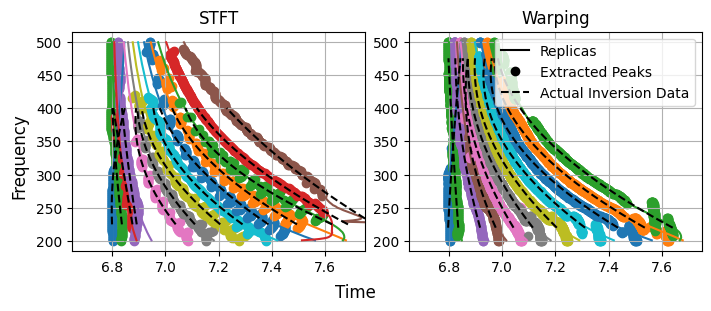

In [64]:
fig, (ax_full, ax_warped) = plt.subplots(1,2, layout="constrained")

for ind, p in enumerate(data_full['peaks_coordinates']):
    mode_no = data_full['mode_nos'][ind]
    color = f"C{mode_no}"
    ax_full.scatter(p[:,1], p[:,0], c=color)
    ax_full.plot(at_reference[mode_no], f_Vg, c=color)
    
ax_full.set_prop_cycle(None)
ax_full.plot(arrival_times_full.T, regression_f, 'k--')

ax_full.set_xlim([6.65, 7.75])

ax_full.grid()

ax_full.set_title("STFT")

for ind, p in enumerate(data_warped['peaks_coordinates']):
    mode_no = data_warped['mode_nos'][ind]
    color = f"C{mode_no}"
    ax_warped.scatter(p[:,1], p[:,0], c=color)
    ax_warped.plot(at_reference[mode_no], f_Vg, c=color)

ax_warped.set_prop_cycle(None)
ax_warped.plot(arrival_times_warped.T, regression_fw, 'k--')

ax_warped.set_xlim([6.65, 7.75])

ax_warped.grid()

ax_warped.set_title("Warping")

ax_warped.plot(0, 200, 'k-', label='Replicas')
ax_warped.plot(0, 200, 'ko', label='Extracted Peaks')
ax_warped.plot(0, 200, 'k--', label='Actual Inversion Data')

ax_warped.legend()

fig.supylabel("Frequency")
fig.supxlabel("Time")

fig.set_size_inches([7, 3])

fig.savefig("../data/output/mode_curves.png", dpi=600)

## Likelihoods

In [382]:
normalize = lambda x: x/np.sum(x)

In [383]:
l_full = ai.AcousticInversionLikelihood(arrival_times_full[modes_full])
l_warp = ai.AcousticInversionLikelihood(arrival_times_warped[modes_warp])

In [384]:
lk_full = l_full.likelihood(arrival_times_replica_full[:,:, data_full['mode_nos'][modes_full]], 1e0)
lk_warp = l_warp.likelihood(arrival_times_replica_warped[:,:, data_warped['mode_nos'][modes_warp]], 1e0)

In [385]:
RR = ai.calculate_residual(arrival_times_full, arrival_times_replica_full[:,:, data_full['mode_nos']])

In [386]:
lk_full = normalize(lk_full)
lk_warp = normalize(lk_warp)

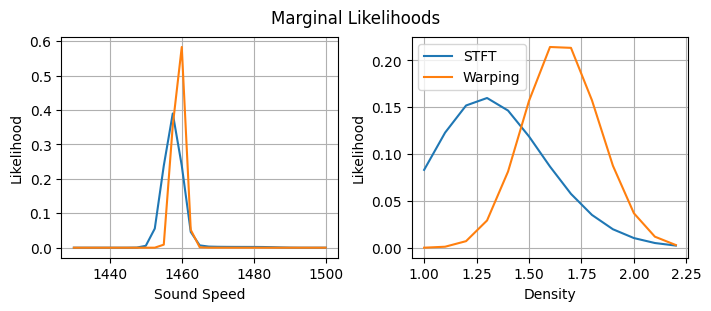

In [387]:
fig, (ax, ax_rho) = plt.subplots(1,2,layout="constrained")

ax.plot(c, lk_full.sum(0), label="Spectrogram")
ax.plot(c, lk_warp.sum(0), label="Warped")

ax.grid()


ax.set_xlabel("Sound Speed")
ax.set_ylabel("Likelihood")

## AX RHO

ax_rho.plot(rho, lk_full.sum(1), label="STFT")
ax_rho.plot(rho, lk_warp.sum(1), label="Warping")

ax_rho.grid()

ax_rho.legend()


ax_rho.set_xlabel("Density")
ax_rho.set_ylabel("Likelihood")

fig.suptitle("Marginal Likelihoods")

fig.set_size_inches([7,3])

fig.savefig("../data/output/likelihood_density_soundspeed.png", dpi=600)

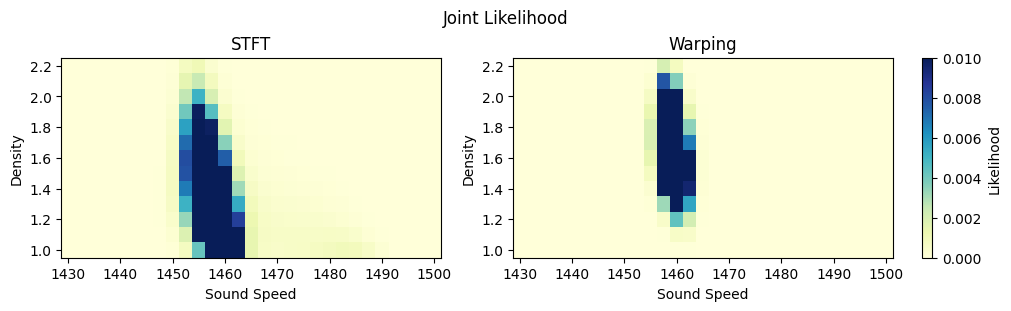

In [388]:
fig, (ax_full, ax_warp) = plt.subplots(1,2, layout="constrained")

vmin, vmax = (0, 0.01)

m1 = ax_full.pcolormesh(c, rho, lk_full, vmin=vmin, vmax=vmax, cmap="YlGnBu")
ax_full.set_xlabel("Sound Speed")
ax_full.set_ylabel("Density")
ax_full.set_title("STFT")
#plt.colorbar(m1, ax=ax_full)

m1 = ax_warp.pcolormesh(c, rho, lk_warp, vmin=vmin, vmax=vmax, cmap="YlGnBu")
ax_warp.set_xlabel("Sound Speed")
ax_warp.set_ylabel("Density")
ax_warp.set_title("Warping")
plt.colorbar(m1, ax=ax_warp, label="Likelihood")

fig.suptitle("Joint Likelihood")

fig.set_size_inches([10,3])

fig.savefig("../data/output/figures/rhoc_joint_likelihood.png", dpi=600)


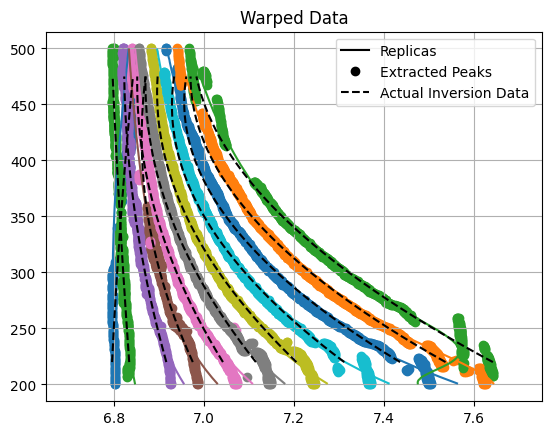

In [389]:
fig, ax_warped = plt.subplots()

# at_wmin = receiver_range/Vg[np.argmin(lk_warp.sum(1)), np.argmin(lk_warp.sum(0))]
at_wmin = receiver_range/Vg[11, c==1460].squeeze()

for ind, p in enumerate(data_warped['peaks_coordinates']):
    mode_no = data_warped['mode_nos'][ind]
    color = f"C{mode_no}"
    ax_warped.scatter(p[:,1], p[:,0], c=color)
    ax_warped.plot(at_wmin[mode_no], f_Vg, c=color)

ax_warped.set_prop_cycle(None)
ax_warped.plot(arrival_times_warped.T, regression_fw, 'k--')

ax_warped.set_xlim([6.65, 7.75])

ax_warped.grid()

ax_warped.set_title("Warped Data")

ax_warped.plot(0, 200, 'k-', label='Replicas')
ax_warped.plot(0, 200, 'ko', label='Extracted Peaks')
ax_warped.plot(0, 200, 'k--', label='Actual Inversion Data')

ax_warped.legend()
